# Day 41 | Turn Profile Text Into Clear Fields

**KGP Talkie**

Clean a page, extract sections, and combine a checked profile record.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

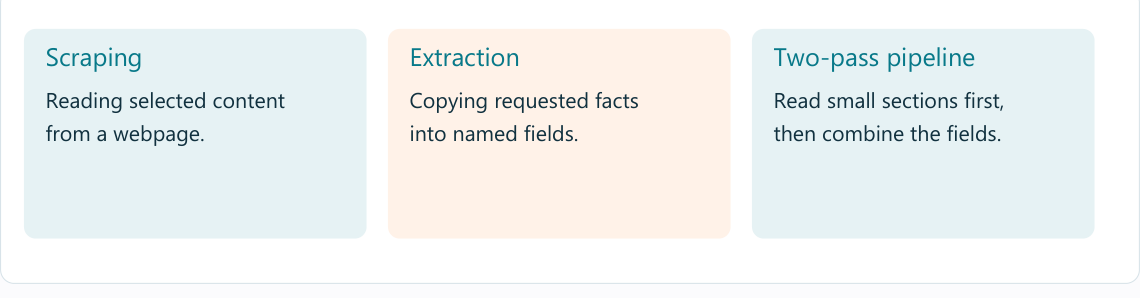

In [4]:
from bs4 import BeautifulSoup
from pydantic import BaseModel, Field

In [5]:
soup = BeautifulSoup((ASSETS / "profile.html").read_text(), "html.parser")

In [6]:
sections = [section.get_text("\n", strip=True) for section in soup.select("main section")]
print(sections)

['About\nAsha teaches Python in Pune.', 'Skills\nPython, Pandas']


In [7]:
context = soup.select_one("main").get_text("\n", strip=True)
print(context)

Asha
About
Asha teaches Python in Pune.
Skills
Python, Pandas


The schema defines fields. city can be missing, and skills is a list of text values.

In [8]:
class Profile(BaseModel):
    name: str
    city: str | None = Field(default=None, description="City only if stated; otherwise null")
    skills: list[str]

ChatOllama sends chat requests to the local Ollama server.

In [9]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [10]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 256-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [11]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=256, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [12]:
extract = llm.with_structured_output(Profile, method="json_schema")

First model pass: extract the facts. Keep this intermediate text visible, as in the course's two-pass workflow.

In [13]:
draft = llm.invoke("Extract name, city, and skills from this fictional profile. Copy stated facts only; keep missing fields empty.\n" + context).content
print(draft)

Here is the extracted information:

Name: Asha
City: Pune
Skills:
  - Python
  - Pandas


Second model pass: put the first extraction into named fields. It can still lose facts, so check the source next.

In [14]:
result = extract.invoke("Format these extracted facts as the schema. Use JSON null if city is missing.\n" + draft)
result.model_dump()

{'name': 'Asha', 'city': 'Pune', 'skills': ['Python', 'Pandas']}

This expected record comes from the supplied HTML. False is a real model error, not a parser failure.

In [15]:
expected = {"name": "Asha", "city": "Pune", "skills": ["Python", "Pandas"]}
print("Matches known sample facts:", result.model_dump() == expected)

Matches known sample facts: True


In [16]:
fresh = extract.invoke("Extract only stated facts: Ravi. Skills: Python. No city is listed.")
fresh.model_dump()

{'name': 'Ravi', 'city': None, 'skills': ['Python']}

In [17]:
(OUTPUT / "profile.json").write_text(result.model_dump_json(indent=2), encoding="utf-8")

84

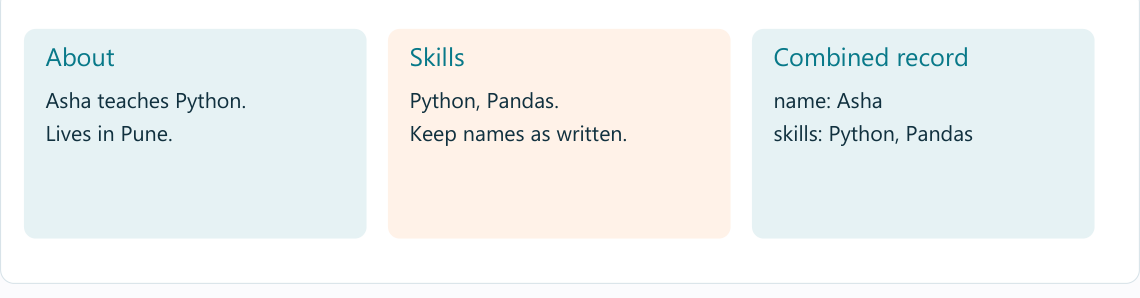

## Try a fresh input

Try a second profile with a missing city. Keep that field empty rather than guessing.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-linkedin-scraping).